# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama: Diky Eka Purnomo
- NIM: 241011402889
- Kelas: Reg C


## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [4]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# GANTI dengan 2 digit terakhir NIM. Jika 00, gunakan 100.
RANDOM_STATE = 89


In [5]:
def train_test_split(X, y, test_size=0.2, random_state=42):
    """Split data tanpa scikit-learn; X dan y diacak dengan indeks yang sama."""
    X = np.asarray(X)
    y = np.asarray(y)
    rng = np.random.RandomState(random_state)
    idx = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

class LinearRegression:
    """Regresi linear dengan normal equation."""
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_ = float(theta[0, 0])
        self.coef_ = theta[1:, 0]
        return self
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_

class LinearRegressionGD:
    """Regresi linear dengan gradient descent; fitur dan target dinormalisasi agar stabil."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        self.x_mean_ = X.mean(axis=0)
        self.x_std_ = X.std(axis=0)
        self.x_std_[self.x_std_ == 0] = 1.0
        self.y_mean_ = y.mean()
        self.y_std_ = y.std() or 1.0
        Xs = (X - self.x_mean_) / self.x_std_
        ys = (y - self.y_mean_) / self.y_std_
        X_b = np.c_[np.ones((len(Xs), 1)), Xs]
        theta = np.zeros(X_b.shape[1])
        for _ in range(self.n_iterations):
            error = X_b @ theta - ys
            theta -= self.learning_rate * (2 / len(ys)) * (X_b.T @ error)
            self.loss_history.append(float(np.mean((X_b @ theta - ys) ** 2) * self.y_std_**2))
        self.coef_ = theta[1:] * self.y_std_ / self.x_std_
        self.intercept_ = float(self.y_mean_ + self.y_std_ * theta[0] - np.sum(self.coef_ * self.x_mean_))
        return self
    def predict(self, X):
        return self.intercept_ + np.asarray(X, dtype=float) @ self.coef_

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

class LogisticRegression:
    """Logistic regression binary dengan gradient descent."""
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1
        Xs = (X - self.mean_) / self.std_
        X_b = np.c_[np.ones(len(Xs)), Xs]
        theta = np.zeros(X_b.shape[1])
        for _ in range(self.n_iterations):
            p = sigmoid(X_b @ theta)
            grad = X_b.T @ (p - y) / len(y)
            theta -= self.learning_rate * grad
            p2 = np.clip(sigmoid(X_b @ theta), 1e-12, 1-1e-12)
            self.loss_history.append(float(-np.mean(y*np.log(p2)+(1-y)*np.log(1-p2))))
        # Simpan parameter dalam skala fitur asli agar persamaan mudah ditafsirkan.
        self.coef_ = theta[1:] / self.std_
        self.intercept_ = float(theta[0] - np.sum(theta[1:] * self.mean_ / self.std_))
        return self
    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        return sigmoid(self.intercept_ + X @ self.coef_)
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

def accuracy_score(y_true, y_pred):
    return np.mean(np.asarray(y_true).reshape(-1) == np.asarray(y_pred).reshape(-1))

def confusion_matrix(y_true, y_pred):
    yt, yp = np.asarray(y_true).astype(int).reshape(-1), np.asarray(y_pred).astype(int).reshape(-1)
    return np.array([[np.sum((yt==0)&(yp==0)), np.sum((yt==0)&(yp==1))],
                     [np.sum((yt==1)&(yp==0)), np.sum((yt==1)&(yp==1))]])

def classification_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    return {'Accuracy': (tp+tn)/(tp+tn+fp+fn), 'Precision':precision, 'Recall':recall, 'F1':f1,
            'TN':tn,'FP':fp,'FN':fn,'TP':tp}


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

Jumlah baris: 40


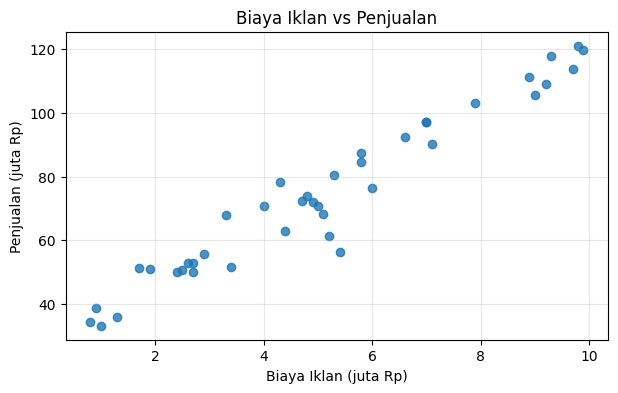

In [8]:
# Jawaban A1
ads = pd.read_csv('Ads_Data.csv')
display(ads.head())
print('Jumlah baris:', len(ads))
X = ads[['BiayaIklan']].to_numpy(dtype=float)  # bentuk (n, 1)
y = ads['Penjualan'].to_numpy(dtype=float)
plt.figure(figsize=(7, 4))
plt.scatter(X[:, 0], y, alpha=0.8)
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, alpha=0.3)
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [10]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [12]:
# Jawaban A3
lin = LinearRegression().fit(X_train, y_train)
print(f'Intercept (b): {lin.intercept_:.4f}')
print(f'Koefisien (m): {lin.coef_[0]:.4f}')
print(f'Persamaan: y_hat = {lin.intercept_:.4f} + ({lin.coef_[0]:.4f})X')


Intercept (b): 27.5570
Koefisien (m): 9.1762
Persamaan: y_hat = 27.5570 + (9.1762)X


**Jawaban A3 (interpretasi):**

Koefisien `m` menunjukkan perubahan prediksi penjualan (juta rupiah) untuk setiap kenaikan biaya iklan sebesar 1 juta rupiah. Jalankan sel A3 untuk melihat nilai `m`; jika positif, penjualan diperkirakan meningkat sebesar `m` juta rupiah per tambahan 1 juta rupiah biaya iklan, dengan faktor lain dianggap tetap. Jika negatif, hubungan prediksinya menurun.


### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [15]:
# Jawaban A4
def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).reshape(-1), np.asarray(y_pred).reshape(-1)
    mse = np.mean((y_true-y_pred)**2)
    denom = np.sum((y_true-y_true.mean())**2)
    return {'MAE':np.mean(np.abs(y_true-y_pred)), 'MSE':mse, 'RMSE':np.sqrt(mse),
            'R2':1-np.sum((y_true-y_pred)**2)/denom if denom else np.nan}
metrics_reg = pd.DataFrame([
    {'Data':'Training', **regression_metrics(y_train, lin.predict(X_train))},
    {'Data':'Testing', **regression_metrics(y_test, lin.predict(X_test))}
]).set_index('Data')
display(metrics_reg.round(4))


**Jawaban A4 (analisis):**

RMSE mengukur besarnya kesalahan prediksi tipikal dalam satuan penjualan (juta rupiah); semakin kecil semakin baik. R² membandingkan model dengan prediksi sederhana berupa rata-rata target: mendekati 1 berarti model menjelaskan variasi dengan baik, sekitar 0 berarti tidak lebih baik dari rata-rata, dan negatif berarti lebih buruk pada data tersebut. Nilai pada tabel testing menjadi acuan utama untuk menilai kemampuan pada data baru. Bandingkan nilai training dan testing; selisih besar dapat mengindikasikan generalisasi yang kurang baik.


### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

lr=0.001: intercept=27.56, koefisien=9.176, loss akhir=35.79
lr=0.02: intercept=27.56, koefisien=9.176, loss akhir=35.79
lr=0.1: intercept=27.56, koefisien=9.176, loss akhir=35.79
Normal equation: 27.557043046270028 9.176249240282234


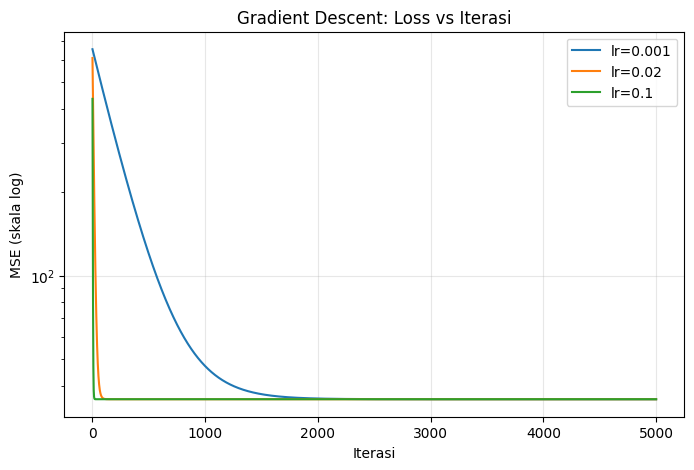

In [18]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
plt.figure(figsize=(8,5))
for lr in learning_rates:
    with np.errstate(over='ignore', invalid='ignore'):
        model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model
    print(f'lr={lr}: intercept={model.intercept_:.4g}, koefisien={model.coef_[0]:.4g}, loss akhir={model.loss_history[-1]:.4g}')
    losses = np.asarray(model.loss_history)
    plt.plot(np.arange(1,len(losses)+1), np.maximum(losses, 1e-12), label=f'lr={lr}')
plt.yscale('log')
plt.xlabel('Iterasi'); plt.ylabel('MSE (skala log)')
plt.title('Gradient Descent: Loss vs Iterasi'); plt.legend(); plt.grid(True, alpha=.3); plt.show()
print('Normal equation:', lin.intercept_, lin.coef_[0])


**Jawaban A5 (analisis):**

Gunakan grafik loss dan parameter akhir untuk membandingkan tiap learning rate. Learning rate yang terlalu kecil menurunkan loss lambat; learning rate yang sesuai menurunkan loss dengan stabil dan mendekati hasil normal equation. Learning rate terlalu besar dapat membuat loss melonjak, overflow, atau divergen. Jika fitur tidak dinormalisasi, besarnya skala `BiayaIklan` juga memengaruhi ukuran langkah gradient descent. Periksa kurva aktual sebelum menetapkan mana yang lambat, sesuai, atau divergen.


### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

Biaya iklan 4.5 juta -> prediksi penjualan 68.850 juta Rp
Biaya iklan 7 juta -> prediksi penjualan 91.791 juta Rp
Biaya iklan 12 juta -> prediksi penjualan 137.672 juta Rp


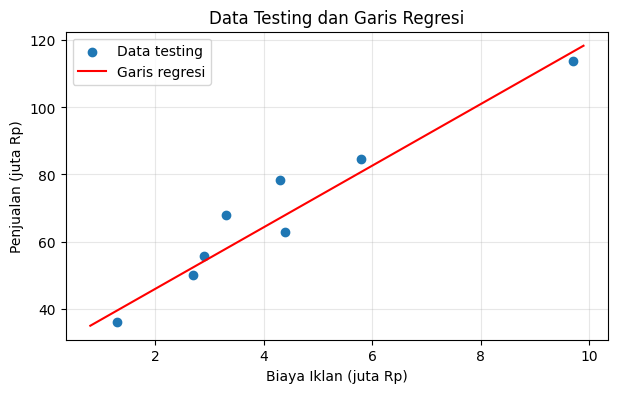

In [21]:
# Jawaban A6
plt.figure(figsize=(7,4))
plt.scatter(X_test[:,0], y_test, label='Data testing')
xline = np.linspace(min(X[:,0]), max(X[:,0]), 200).reshape(-1,1)
plt.plot(xline[:,0], lin.predict(xline), color='red', label='Garis regresi')
plt.xlabel('Biaya Iklan (juta Rp)'); plt.ylabel('Penjualan (juta Rp)')
plt.title('Data Testing dan Garis Regresi'); plt.legend(); plt.grid(True, alpha=.3); plt.show()
new_ads = np.array([[4.5],[7.0],[12.0]])
for xval, pred in zip(new_ads[:,0], lin.predict(new_ads)):
    print(f'Biaya iklan {xval:g} juta -> prediksi penjualan {pred:.3f} juta Rp')


**Jawaban A6 (analisis):**

Prediksi pada 4,5 dan 7 juta lebih dapat dipercaya apabila nilainya masih berada dalam rentang biaya iklan yang diamati. Prediksi 12 juta merupakan ekstrapolasi jika berada di luar rentang data training; hubungan linear yang terlihat pada data lama belum tentu berlanjut sejauh itu. Karena itu, prediksi 12 juta perlu dianggap lebih tidak pasti dan sebaiknya didukung data tambahan pada rentang tersebut.


---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

Jumlah tiap kelas (0=Bukan Spam, 1=Spam):
Spam
Bukan Spam    35
Spam          25
Name: count, dtype: int64


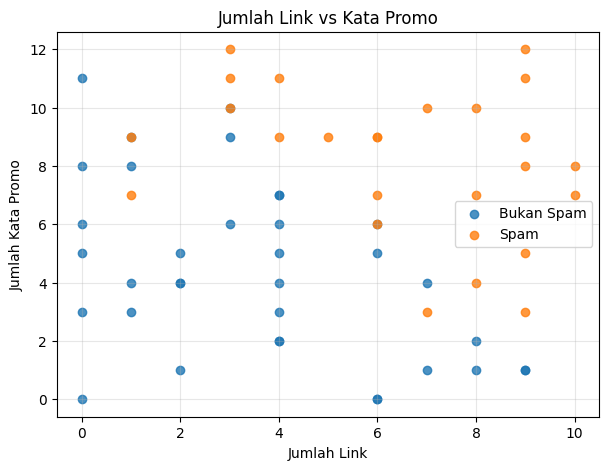

In [25]:
# Jawaban B1
emails = pd.read_csv('Email_Data.csv')
display(emails.head())
print('Jumlah tiap kelas (0=Bukan Spam, 1=Spam):')
print(emails['Spam'].value_counts().sort_index().rename(index={0:'Bukan Spam',1:'Spam'}))
X_email = emails[['JumlahLink','KataPromo']].to_numpy(dtype=float)
y_email = emails['Spam'].to_numpy(dtype=int)
plt.figure(figsize=(7,5))
for label, name, color in [(0,'Bukan Spam','tab:blue'),(1,'Spam','tab:orange')]:
    mask = y_email == label
    plt.scatter(X_email[mask,0], X_email[mask,1], label=name, alpha=.8, color=color)
plt.xlabel('Jumlah Link'); plt.ylabel('Jumlah Kata Promo')
plt.title('Jumlah Link vs Kata Promo'); plt.legend(); plt.grid(True, alpha=.3); plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b): -15.101992
m1 (JumlahLink): 1.230939
m2 (KataPromo): 1.232521
P(Spam) = sigmoid(-15.1020 + (1.2309)*JumlahLink + (1.2325)*KataPromo)


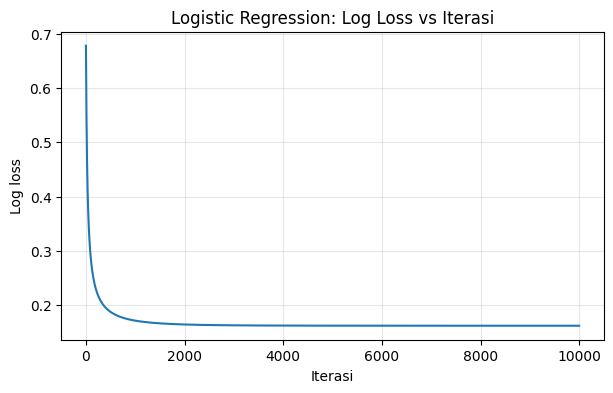

In [27]:
# Jawaban B2
Xtr, Xte, ytr, yte = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)
logit = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xtr, ytr)
print(f'Intercept (b): {logit.intercept_:.6f}')
print(f'm1 (JumlahLink): {logit.coef_[0]:.6f}')
print(f'm2 (KataPromo): {logit.coef_[1]:.6f}')
print(f'P(Spam) = sigmoid({logit.intercept_:.4f} + ({logit.coef_[0]:.4f})*JumlahLink + ({logit.coef_[1]:.4f})*KataPromo)')
plt.figure(figsize=(7,4)); plt.plot(logit.loss_history)
plt.xlabel('Iterasi'); plt.ylabel('Log loss'); plt.title('Logistic Regression: Log Loss vs Iterasi')
plt.grid(True, alpha=.3); plt.show()


**Jawaban B2 (analisis):**

Koefisien positif menaikkan log-odds spam ketika fitur tersebut meningkat, sedangkan koefisien negatif menurunkannya, dengan fitur lain tetap. Periksa grafik log loss: model belajar dengan baik bila loss turun lalu relatif stabil. Karena fitur distandardisasi saat pelatihan, tetapi koefisien dikembalikan ke skala fitur asli untuk prediksi, persamaan yang dicetak dapat digunakan langsung dengan jumlah link dan kata promo.


### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [30]:
# Jawaban B3
y_pred = logit.predict(Xte, threshold=0.5)
cm = confusion_matrix(yte, y_pred)
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(cm)
display(pd.DataFrame([classification_metrics(yte, y_pred)]).round(4))


Confusion matrix [[TN, FP], [FN, TP]]:
[[4 0]
 [4 7]]


**Jawaban B3 (analisis):**

FP (false positive) adalah email bukan spam yang keliru ditandai sebagai spam, sehingga pesan penting bisa masuk folder spam. FN (false negative) adalah email spam yang lolos ke inbox. Kesalahan yang lebih merugikan bergantung pada kebutuhan pengguna: untuk menghindari hilangnya email penting, FP sangat merugikan; untuk keamanan dan mengurangi pesan berbahaya, FN juga penting. Confusion matrix testing menunjukkan jumlah masing-masing kesalahan pada model ini.


### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Indeks lokal testing yang salah klasifikasi: [4, 5, 11, 12]
Data salah klasifikasi (fitur, aktual, prediksi):
4 [9.0, 3.0] 1 0
5 [6.0, 6.0] 1 0
11 [7.0, 3.0] 1 0
12 [1.0, 7.0] 1 0


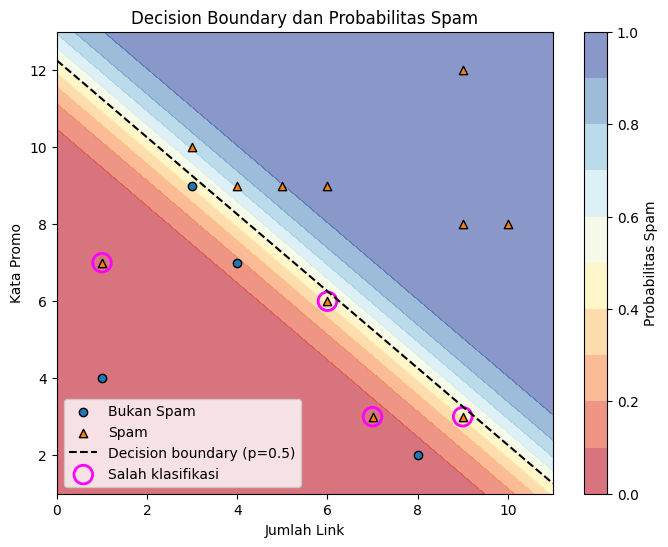

In [33]:
# Jawaban B4
probs = logit.predict_proba(Xte)
mis = y_pred != yte
x1_min, x1_max = Xte[:,0].min()-1, Xte[:,0].max()+1
x2_min, x2_max = Xte[:,1].min()-1, Xte[:,1].max()+1
grid1, grid2 = np.meshgrid(np.linspace(x1_min,x1_max,200), np.linspace(x2_min,x2_max,200))
grid = np.c_[grid1.ravel(), grid2.ravel()]
pg = logit.predict_proba(grid).reshape(grid1.shape)
plt.figure(figsize=(8,6)); plt.contourf(grid1, grid2, pg, levels=np.linspace(0,1,11), cmap='RdYlBu', alpha=.6)
plt.colorbar(label='Probabilitas Spam')
for label, name, marker in [(0,'Bukan Spam','o'),(1,'Spam','^')]:
    m = yte == label
    plt.scatter(Xte[m,0], Xte[m,1], marker=marker, edgecolors='black', label=name)
if abs(logit.coef_[1]) > 1e-12:
    xx = np.linspace(x1_min,x1_max,200)
    yy = -(logit.intercept_ + logit.coef_[0]*xx)/logit.coef_[1]
    plt.plot(xx, yy, 'k--', label='Decision boundary (p=0.5)')
if np.any(mis):
    plt.scatter(Xte[mis,0], Xte[mis,1], s=180, facecolors='none', edgecolors='magenta', linewidths=2, label='Salah klasifikasi')
print('Indeks lokal testing yang salah klasifikasi:', np.where(mis)[0].tolist())
print('Data salah klasifikasi (fitur, aktual, prediksi):')
for i in np.where(mis)[0]: print(i, Xte[i].tolist(), int(yte[i]), int(y_pred[i]))
plt.xlabel('Jumlah Link'); plt.ylabel('Kata Promo'); plt.title('Decision Boundary dan Probabilitas Spam'); plt.legend(); plt.show()


**Jawaban B4 (analisis):**

Decision boundary adalah garis ketika probabilitas spam sama dengan 0,5. Area background memperlihatkan probabilitas yang diprediksi model, sementara lingkaran magenta menandai data testing yang salah klasifikasi. Indeks dan nilai aktual/prediksi ditampilkan oleh kode agar kesalahan dapat diperiksa satu per satu.


### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [36]:
# Jawaban B5
rows = []
for threshold in [0.3, 0.5, 0.7]:
    pred_t = (logit.predict_proba(Xte) >= threshold).astype(int)
    cm_t = confusion_matrix(yte, pred_t)
    m = classification_metrics(yte, pred_t)
    rows.append({'Threshold':threshold, 'TN':cm_t[0,0], 'FP':cm_t[0,1], 'FN':cm_t[1,0], 'TP':cm_t[1,1],
                 'Precision':m['Precision'], 'Recall':m['Recall']})
display(pd.DataFrame(rows).set_index('Threshold').round(4))


**Jawaban B5 (analisis):**

Threshold lebih rendah biasanya membuat lebih banyak email diprediksi sebagai spam: recall cenderung naik, tetapi FP dapat bertambah dan precision dapat turun. Threshold lebih tinggi biasanya mengurangi FP, tetapi lebih banyak spam bisa lolos sehingga recall cenderung turun. Pilih threshold berdasarkan konsekuensi kesalahan pada Soal B3 dan tabel hasil nyata; jika email penting tidak boleh mudah masuk folder spam, threshold 0,7 bisa dipertimbangkan, sedangkan jika spam harus lebih banyak tertangkap, 0,3 bisa dipertimbangkan. Keputusan akhir harus mengikuti metrik yang dihasilkan.


### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [39]:
# Jawaban B6
# Threshold pilihan awal: 0.5. Ubah jika hasil analisis B5 mendukung threshold lain.
THRESHOLD_PILIHAN = 0.5
email_baru = pd.DataFrame({'Email':['E1','E2','E3','E4'], 'JumlahLink':[1,5,9,2], 'KataPromo':[2,6,10,11]})
X_baru = email_baru[['JumlahLink','KataPromo']].to_numpy(dtype=float)
email_baru['Probabilitas_Spam'] = logit.predict_proba(X_baru)
email_baru['Prediksi'] = (email_baru['Probabilitas_Spam'] >= THRESHOLD_PILIHAN).astype(int)
email_baru['Kelas'] = email_baru['Prediksi'].map({0:'Bukan Spam',1:'Spam'})
display(email_baru.round(4))
print('Threshold yang digunakan:', THRESHOLD_PILIHAN)


Threshold yang digunakan: 0.5


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression disebut klasifikasi karena digunakan untuk memprediksi kelas, misalnya spam atau bukan spam, bukan untuk memprediksi nilai kontinu. Model menghitung kombinasi linear fitur lalu memasukkannya ke fungsi sigmoid. Sigmoid mengubah skor menjadi nilai antara 0 dan 1 yang dapat ditafsirkan sebagai probabilitas kelas positif. Threshold digunakan untuk mengubah probabilitas tersebut menjadi label kelas.

**Jawaban C2:** Normal equation menghitung parameter secara langsung melalui operasi matriks dan tidak memerlukan iterasi learning rate. Gradient descent memperbarui parameter berulang kali mengikuti arah gradien loss. Gradient descent berguna untuk dataset besar atau banyak fitur ketika penyelesaian matriks mahal, tetapi hasilnya dipengaruhi learning rate dan jumlah iterasi. Normal equation praktis untuk masalah kecil dengan jumlah fitur sedikit.

**Jawaban C3:** Data testing dipakai untuk mengukur performa pada data yang tidak digunakan saat pelatihan, sehingga lebih menggambarkan kemampuan generalisasi. Evaluasi training saja dapat terlihat bagus karena model telah belajar dari data tersebut. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training, termasuk noise, sehingga performa pada data baru memburuk. Karena itu hasil training dan testing perlu dibandingkan.

**Jawaban C4:** Linear Regression memprediksi nilai kontinu sehingga MSE mengukur kuadrat selisih antara nilai aktual dan prediksi. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss menilai seberapa baik probabilitas tersebut sesuai label sebenarnya. Log loss memberi penalti besar pada prediksi probabilitas yang sangat yakin tetapi salah. Masing-masing loss sesuai dengan jenis output dan tujuan modelnya.

**Jawaban C5:** Hasil dapat berbeda karena pembagian data training/testing dipengaruhi `random_state`, yang pada tugas ini ditentukan dari dua digit terakhir NIM. Pembagian yang berbeda menghasilkan sampel pelatihan berbeda dan dapat mengubah koefisien maupun metrik. Untuk Logistic Regression, learning rate, jumlah iterasi, standardisasi fitur, dan pengaturan optimisasi juga berpengaruh. Perbandingan yang adil memerlukan dataset, split, dan pengaturan yang sama.


---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [43]:
# Jawaban Bonus
try:
    from sklearn.linear_model import LinearRegression as SKLinearRegression
    from sklearn.linear_model import LogisticRegression as SKLogisticRegression
    from sklearn.metrics import accuracy_score as sk_accuracy_score, mean_squared_error, r2_score

    sk_lin = SKLinearRegression().fit(X_train, y_train)
    print('Linear Regression - implementasi sendiri:', 'intercept=', lin.intercept_, 'coef=', lin.coef_)
    print('Linear Regression - scikit-learn:', 'intercept=', sk_lin.intercept_, 'coef=', sk_lin.coef_)
    print('R2 testing sendiri:', regression_metrics(y_test, lin.predict(X_test))['R2'])
    print('R2 testing scikit-learn:', r2_score(y_test, sk_lin.predict(X_test)))

    # C mendekati tak hingga mengurangi regularisasi; solver dan toleransi tetap dapat menimbulkan selisih.
    sk_log = SKLogisticRegression(C=1e6, max_iter=10000, solver='lbfgs')
    sk_log.fit(Xtr, ytr)
    sk_pred = sk_log.predict(Xte)
    print('Logistic Regression - implementasi sendiri:', 'intercept=', logit.intercept_, 'coef=', logit.coef_)
    print('Logistic Regression - scikit-learn:', 'intercept=', sk_log.intercept_[0], 'coef=', sk_log.coef_[0])
    print('Accuracy testing sendiri:', accuracy_score(yte, logit.predict(Xte)))
    print('Accuracy testing scikit-learn:', sk_accuracy_score(yte, sk_pred))
except ImportError:
    print('Paket scikit-learn belum tersedia. Instal scikit-learn untuk menjalankan soal bonus saja.')


Linear Regression - implementasi sendiri: intercept= 27.557043046270028 coef= [9.17624924]
Linear Regression - scikit-learn: intercept= 27.557043046270124 coef= [9.17624924]
R2 testing sendiri: 0.9246374415138208
R2 testing scikit-learn: 0.9246374415138209
Logistic Regression - implementasi sendiri: intercept= -15.101991758763875 coef= [1.2309392  1.23252095]
Logistic Regression - scikit-learn: intercept= -15.14992913998823 coef= [1.23506209 1.23635749]
Accuracy testing sendiri: 0.7333333333333333
Accuracy testing scikit-learn: 0.7333333333333333


**Jawaban Bonus (analisis):**

Implementasi Linear Regression dengan normal equation seharusnya menghasilkan koefisien yang sangat dekat dengan scikit-learn, dengan kemungkinan selisih numerik kecil. Logistic Regression dapat berbeda karena scikit-learn secara default menggunakan regularisasi; parameter `C` adalah kebalikan kekuatan regularisasi, sehingga `C=1e6` membuat regularisasi sangat lemah, bukan menghilangkannya secara matematis. Perbedaan juga dapat berasal dari solver, toleransi konvergensi, dan optimisasi. Bandingkan koefisien serta metrik testing yang tercetak setelah seluruh dataset tersedia.
